# Spatial-Domain Filtering: Smoothing, Sharpening, and Non-Linear Filters

## 1. Lab Overview

This lab implements and compares spatial-domain filtering techniques for image smoothing, noise reduction, sharpening, and detail enhancement. Grayscale images are used to examine pixel neighborhoods and filter responses, followed by experiments on color images.

The practical work covers correlation and convolution, mean and Gaussian smoothing, sharpening kernels, unsharp masking, and non-linear filters, including median, maximum, and minimum filters. The results are compared to understand how each technique affects image details, edges, and noise.

## 2. Learning Outcomes

By completing this lab, I learned to:

1. Load, display, and inspect grayscale and color images using Python.
2. Explain kernels and pixel neighborhoods in spatial filtering.
3. Differentiate correlation from convolution and understand how OpenCV's `filter2D()` operates.
4. Apply mean and Gaussian filters for smoothing and noise reduction.
5. Implement sharpening kernels and unsharp masking to enhance edges and details.
6. Apply median, maximum, and minimum filters and compare their effects.
7. Apply selected filtering techniques to color images and understand channel-wise processing.
8. Analyze filtering results and identify suitable techniques for different image-processing tasks.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.signal import correlate2d, convolve2d

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)


OpenCV: 4.14.0
NumPy: 2.1.3


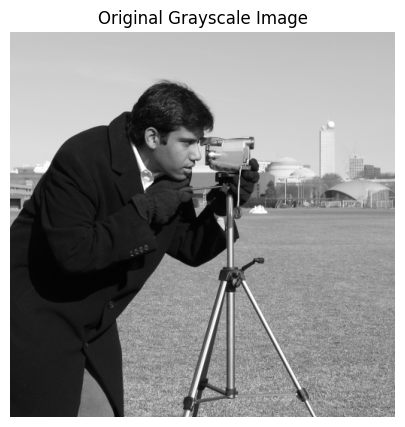

Shape: (512, 512)
Data type: uint8
Minimum intensity: 0
Maximum intensity: 255


In [3]:
# Load and Inspect a Grayscale Image
gray_img = data.camera()  # 8-bit grayscale sample

plt.figure(figsize=(6, 5))
plt.imshow(gray_img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

print("Shape:", gray_img.shape)
print("Data type:", gray_img.dtype)
print("Minimum intensity:", gray_img.min())
print("Maximum intensity:", gray_img.max())


In [4]:
# Understand a Neighborhood and Kernel
kernel = np.ones((3, 3), dtype=np.float32) / 9
print("3x3 mean kernel:")
print(kernel)

neighborhood = np.array([
    [10, 20, 30],
    [20, 40, 60],
    [30, 40, 50]
], dtype=np.float32)
print("Neighborhood mean:", neighborhood.mean())


3x3 mean kernel:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Neighborhood mean: 33.333332


In [5]:
# Correlation versus Convolution
small_img = gray_img[100:104, 100:104].astype(np.float32)
edge_kernel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=np.float32)

corr = correlate2d(small_img, edge_kernel, mode="same", boundary="fill")
conv = convolve2d(small_img, edge_kernel, mode="same", boundary="fill")
print("Small image:\n", small_img)
print("Correlation result:\n", corr)
print("Convolution result:\n", conv)
print("Are results equal?", np.allclose(corr, conv))


Small image:
 [[212. 212. 212. 213.]
 [213. 212. 212. 211.]
 [213. 213. 213. 211.]
 [213. 213. 212. 212.]]
Correlation result:
 [[-636.    1.   -1.  636.]
 [-849.    2.    3.  849.]
 [-851.    2.    6.  850.]
 [-639.    2.    4.  637.]]
Convolution result:
 [[ 636.   -1.    1. -636.]
 [ 849.   -2.   -3. -849.]
 [ 851.   -2.   -6. -850.]
 [ 639.   -2.   -4. -637.]]
Are results equal? False


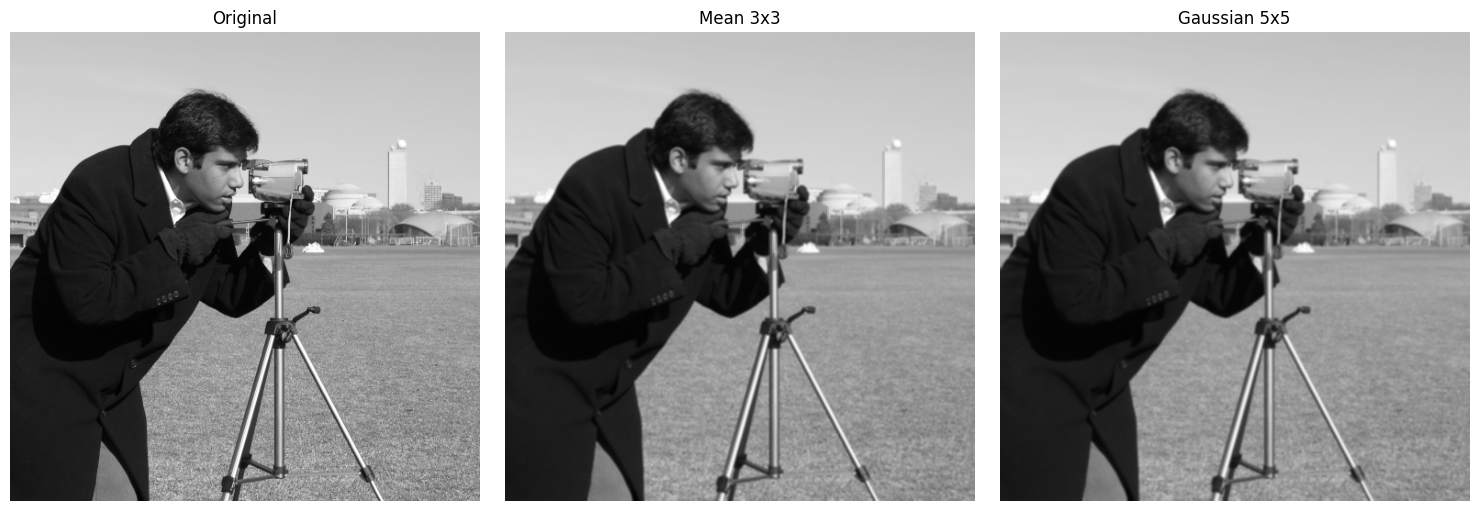

In [6]:
# Mean and Gaussian Smoothing
mean_img = cv2.blur(gray_img, (3, 3))
gaussian_img = cv2.GaussianBlur(gray_img, (5, 5), sigmaX=1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes,
        [gray_img, mean_img, gaussian_img],
        ["Original", "Mean 3x3", "Gaussian 5x5"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


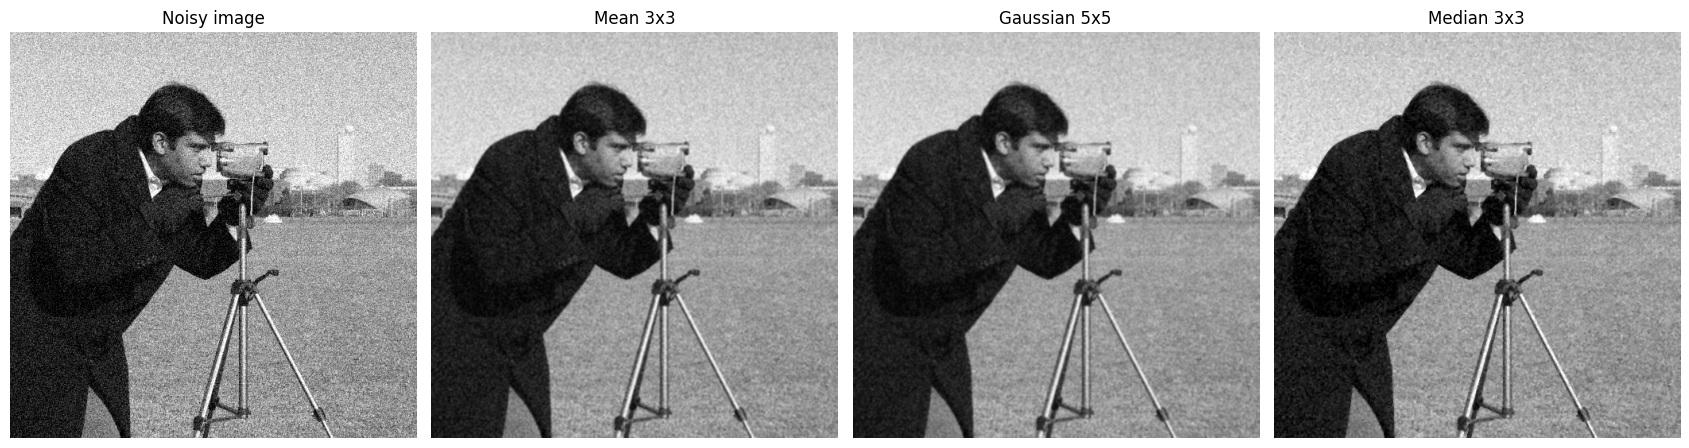

In [8]:
# Compare Filters on a Noisy Image
rng = np.random.default_rng(42)
noise = rng.normal(loc=0, scale=25, size=gray_img.shape)
noisy_img = np.clip(gray_img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

mean_denoised = cv2.blur(noisy_img, (3, 3))
gaussian_denoised = cv2.GaussianBlur(noisy_img, (5, 5), sigmaX=1.0)
median_denoised = cv2.medianBlur(noisy_img, 3)

images = [noisy_img, mean_denoised, gaussian_denoised, median_denoised]

titles = ["Noisy image", "Mean 3x3", "Gaussian 5x5", "Median 3x3"]
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

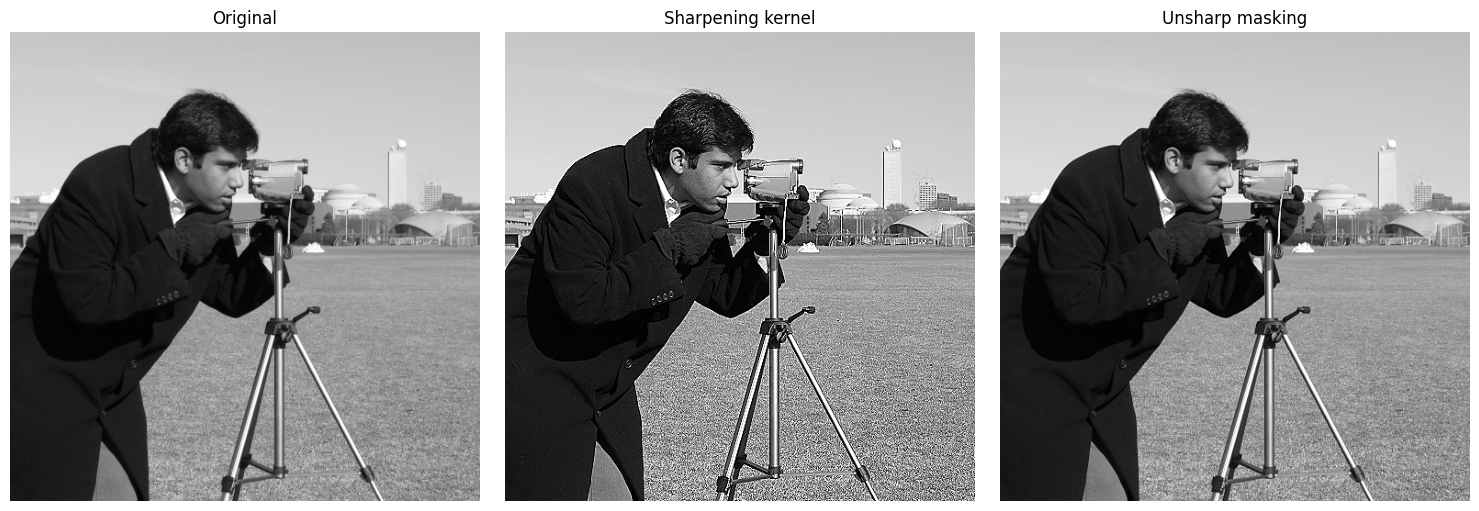

In [ ]:
# Sharpening and Unsharp Masking
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

sharpened_img = cv2.filter2D(gray_img, ddepth=-1, kernel=sharpen_kernel)
blurred_img = cv2.GaussianBlur(gray_img, (5, 5), sigmaX=1.0)
unsharp_img = cv2.addWeighted(gray_img, 1.5, blurred_img, -0.5, 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes,
        [gray_img, sharpened_img, unsharp_img],
        ["Original", "Sharpening kernel", "Unsharp masking"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


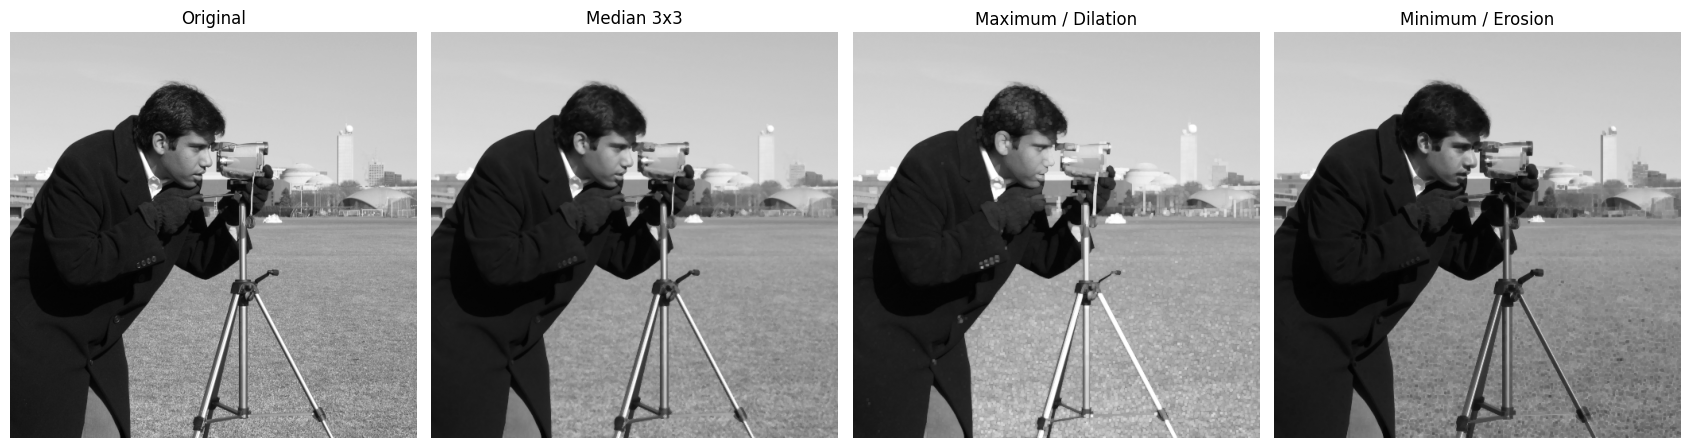

In [ ]:
# Median, Maximum, and Minimum Filters
structuring_element = np.ones((3, 3), dtype=np.uint8)
median_img = cv2.medianBlur(gray_img, 3)
max_img = cv2.dilate(gray_img, structuring_element)
min_img = cv2.erode(gray_img, structuring_element)

images = [gray_img, median_img, max_img, min_img]
titles = ["Original", "Median 3x3", "Maximum / Dilation", "Minimum / Erosion"]
fig, axes = plt.subplots(1, 4, figsize=(17, 5))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()



Shape: (512, 512, 3)
Data type: uint8


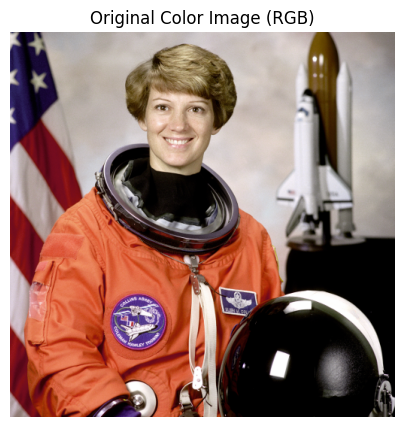

In [ ]:
# Extend Filtering to a Color Image
color_img = data.astronaut()  # RGB image
print("Shape:", color_img.shape)
print("Data type:", color_img.dtype)

plt.figure(figsize=(6, 5))
plt.imshow(color_img)
plt.title("Original Color Image (RGB)")
plt.axis("off")
plt.show()


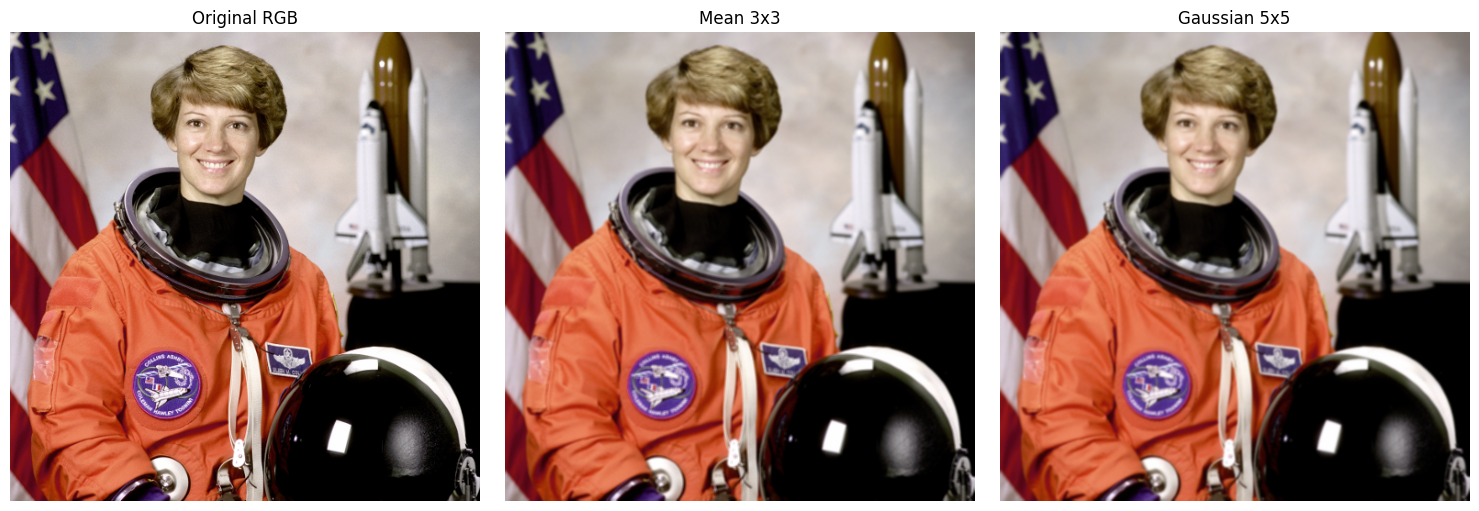

In [ ]:
# Color Smoothing
color_mean = cv2.blur(color_img, (3, 3))
color_gaussian = cv2.GaussianBlur(color_img, (5, 5), sigmaX=1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes,
        [color_img, color_mean, color_gaussian],
        ["Original RGB", "Mean 3x3", "Gaussian 5x5"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


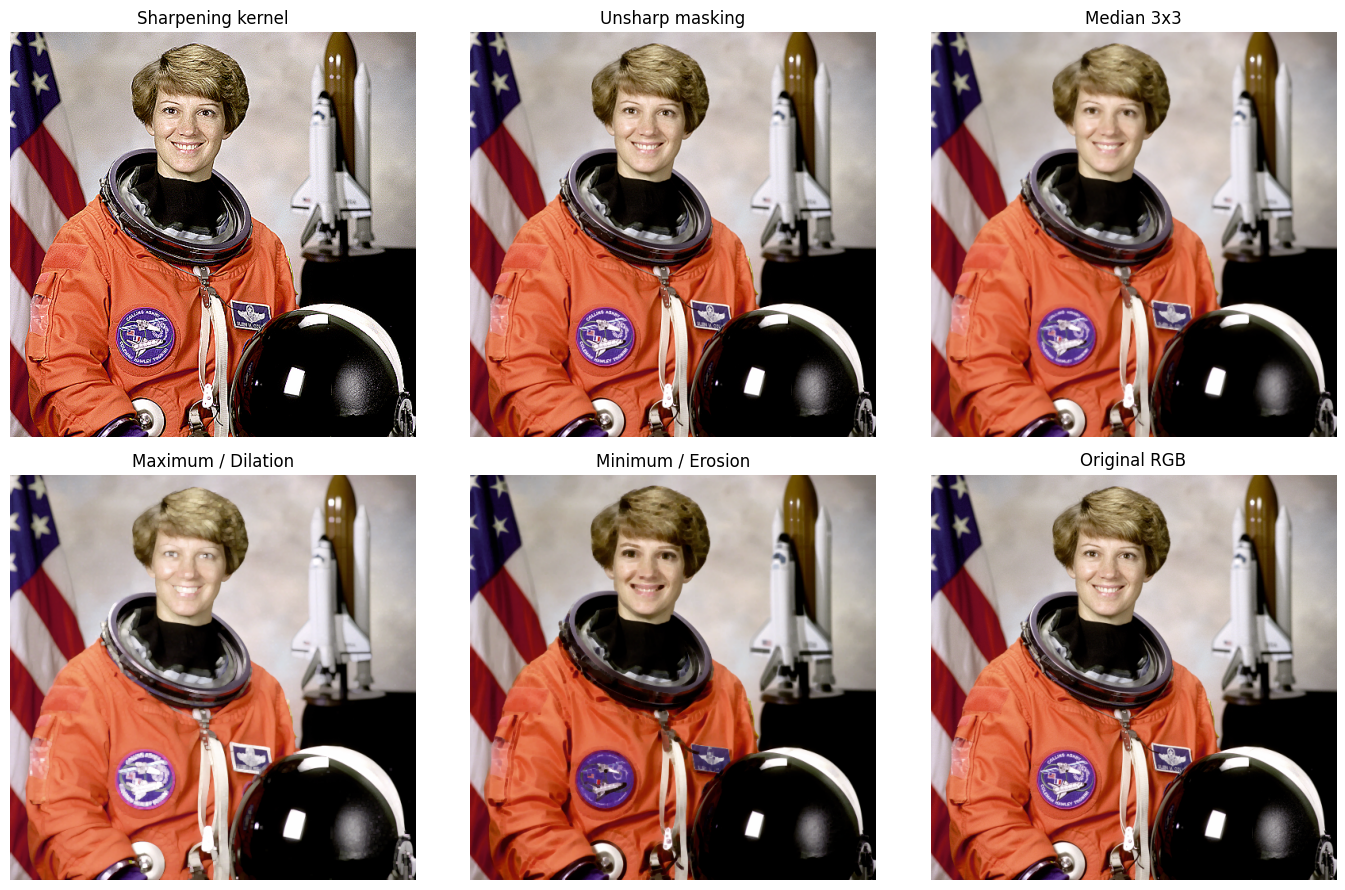

In [ ]:
# Color Sharpening and Order-Statistics Filters
color_sharpened = cv2.filter2D(color_img, ddepth=-1, kernel=sharpen_kernel)
color_blurred = cv2.GaussianBlur(color_img, (5, 5), sigmaX=1.0)
color_unsharp = cv2.addWeighted(color_img, 1.5, color_blurred, -0.5, 0)

color_median = cv2.medianBlur(color_img, 3)
color_max = cv2.dilate(color_img, structuring_element)
color_min = cv2.erode(color_img, structuring_element)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
images = [color_sharpened, color_unsharp, color_median, color_max, color_min, color_img]
titles = ["Sharpening kernel", "Unsharp masking", "Median 3x3",
          "Maximum / Dilation", "Minimum / Erosion", "Original RGB"]
for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
